In [1]:
# Cell 1: Imports, paths, and watershed inputs.
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.enums import Resampling
from rasterio.features import rasterize
from rasterio.warp import reproject
from scipy import ndimage as ndi
from whitebox import WhiteboxTools

from plots import plot_raster_map

project_dir = Path.cwd().resolve().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd().resolve()
input_dir = project_dir / "Input Data"
preprocessing_dir = project_dir / "Preprocessing"
output_dir = project_dir / "Output Data"
feature_dir = output_dir / "feature_layers"
fig_dir = output_dir / "feature_figures"
vector_dir = output_dir / "feature_vectors"
for folder in (feature_dir, fig_dir, vector_dir):
    folder.mkdir(parents=True, exist_ok=True)

watershed_boundary_path = output_dir / "watershedBoundary.shp"
snapped_outlet_path = preprocessing_dir / "outlet_snapped.shp"
watershed_dem_path = output_dir / "watershedDEM.tif"
filled_dem_path = preprocessing_dir / "filledDEM.tif"
flow_accumulation_path = preprocessing_dir / "flowAccumulation.tif"
flow_pointer_path = preprocessing_dir / "flowPointer.tif"

with rasterio.open(watershed_dem_path) as src:
    grid_shape = (src.height, src.width)
    valid_dem = src.read_masks(1) > 0
    crs = src.crs
    transform = src.transform
    cs = abs(src.res[0])
    cell_area = abs(src.transform.a * src.transform.e - src.transform.b * src.transform.d)
watershed_gdf = gpd.read_file(watershed_boundary_path).to_crs(crs)

def align_to_watershed(path, resampling=Resampling.nearest):
    """Reproject a notebook-02 raster onto the clipped watershed DEM grid."""
    aligned = np.full(grid_shape, np.nan, dtype="float32")
    with rasterio.open(path) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=aligned,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=transform,
            dst_crs=crs,
            dst_nodata=np.nan,
            resampling=resampling,
            init_dest_nodata=True,
        )
    aligned[~valid_dem] = np.nan
    return aligned


def save_watershed_tif(arr, name, nodata=-9999.0):
    """Write an aligned grid while preserving the watershed DEM validity mask."""
    if arr.shape != grid_shape:
        raise ValueError(f"{name} grid {arr.shape} does not match watershed DEM {grid_shape}")
    out_path = feature_dir / f"{name}.tif"
    meta = {
        "driver": "GTiff", "height": grid_shape[0], "width": grid_shape[1],
        "count": 1, "dtype": "float32", "crs": crs, "transform": transform,
        "nodata": nodata, "compress": "lzw",
    }
    with rasterio.open(out_path, "w", **meta) as dst:
        for _, window in dst.block_windows(1):
            rows = slice(int(window.row_off), int(window.row_off + window.height))
            cols = slice(int(window.col_off), int(window.col_off + window.width))
            values = np.asarray(arr[rows, cols], dtype="float32").copy()
            values[~valid_dem[rows, cols] | ~np.isfinite(values)] = nodata
            dst.write(values, 1, window=window)
    return out_path


def show_layer(name, arr, title, cbar_label, **kwargs):
    raster_path = save_watershed_tif(arr, name)
    png_path = fig_dir / f"{name}.png"
    fig = plot_raster_map(
        str(raster_path), watershed_gdf, str(snapped_outlet_path),
        title, cbar_label, str(png_path), **kwargs,
    )
    print(f"Saved: {raster_path.name} | {png_path.name}")
    plt.show()
    plt.close(fig)


def save_clipped_raster(source_path, name):
    """Copy a watershed-grid raster while enforcing the DEM's basin mask."""
    output = feature_dir / f"{name}.tif"
    with rasterio.open(source_path) as src:
        if src.shape != grid_shape or src.transform != transform or src.crs != crs:
            raise ValueError(f"{source_path} is not aligned with the watershed DEM grid")
        nodata = src.nodata if src.nodata is not None else -9999.0
        meta = src.profile.copy()
        meta.update(nodata=nodata, compress="lzw")
        with rasterio.open(output, "w", **meta) as dst:
            for _, window in src.block_windows(1):
                rows = slice(int(window.row_off), int(window.row_off + window.height))
                cols = slice(int(window.col_off), int(window.col_off + window.width))
                values = src.read(1, window=window)
                mask = valid_dem[rows, cols] & (src.read_masks(1, window=window) > 0)
                if np.issubdtype(values.dtype, np.floating):
                    values[~mask | ~np.isfinite(values)] = nodata
                else:
                    values[~mask] = nodata
                dst.write(values, 1, window=window)
    return output


def create_whitebox_layer(name, method, *args, **kwargs):
    temporary = feature_dir / f"_{name}_full.tif"
    run_whitebox(method, *args, temporary, **kwargs)
    output = save_clipped_raster(temporary, name)
    temporary.unlink(missing_ok=True)
    return output


def create_tpi_layer(name, radius_m):
    window = 2 * round(radius_m / cs) + 1
    mean_path = feature_dir / f"_{name}_mean.tif"
    run_whitebox(
        "mean_filter", watershed_dem_path, mean_path,
        filterx=window, filtery=window,
    )
    output = feature_dir / f"{name}.tif"
    with rasterio.open(watershed_dem_path) as dem_src, rasterio.open(mean_path) as mean_src:
        nodata = dem_src.nodata if dem_src.nodata is not None else -9999.0
        meta = dem_src.profile.copy()
        meta.update(dtype="float32", nodata=nodata, compress="lzw")
        with rasterio.open(output, "w", **meta) as dst:
            for _, block in dst.block_windows(1):
                elev = dem_src.read(1, window=block)
                local_mean = mean_src.read(1, window=block)
                valid = (
                    (dem_src.read_masks(1, window=block) > 0)
                    & (mean_src.read_masks(1, window=block) > 0)
                    & np.isfinite(elev) & np.isfinite(local_mean)
                )
                values = np.full(elev.shape, nodata, dtype="float32")
                np.subtract(elev, local_mean, out=values, where=valid)
                dst.write(values, 1, window=block)
    mean_path.unlink(missing_ok=True)
    return output


def show_saved_layer(name, raster_path, title, cbar_label, **kwargs):
    png_path = fig_dir / f"{name}.png"
    fig = plot_raster_map(
        str(raster_path), watershed_gdf, str(snapped_outlet_path),
        title, cbar_label, str(png_path), **kwargs,
    )
    print(f"Saved: {raster_path.name} | {png_path.name}")
    plt.show()
    plt.close(fig)


def run_whitebox(method, *args, **kwargs):
    output_path = Path(args[-1])
    if output_path.suffix.lower() == ".shp":
        for suffix in (".shp", ".shx", ".dbf", ".prj", ".cpg"):
            output_path.with_suffix(suffix).unlink(missing_ok=True)
    else:
        output_path.unlink(missing_ok=True)
    result = getattr(wbt, method)(*map(str, args), **kwargs)
    if result != 0 or not output_path.exists():
        raise RuntimeError(f"WhiteboxTools {method} failed to create {output_path}.")


def create_stream_mask_full():
    """Threshold notebook-02 D8 accumulation in native grid cells."""
    output = feature_dir / "_stream_mask_full.tif"
    with rasterio.open(flow_accumulation_path) as accumulation:
        profile = accumulation.profile.copy()
        pixel_area = abs(
            accumulation.transform.a * accumulation.transform.e
            - accumulation.transform.b * accumulation.transform.d
        )
        threshold_cells = 25_000_000.0 / pixel_area
        profile.update(dtype="uint8", nodata=0, compress="lzw")
        with rasterio.open(output, "w", **profile) as dst:
            for _, window in accumulation.block_windows(1):
                values = accumulation.read(1, window=window)
                valid = accumulation.read_masks(1, window=window) > 0
                streams = (valid & (values >= threshold_cells)).astype("uint8")
                dst.write(streams, 1, window=window)
    return output


wbt = WhiteboxTools()
wbt.set_verbose_mode(False)
wbt.set_working_dir(str(preprocessing_dir))
with rasterio.open(flow_accumulation_path) as src:
    flow_source_shape = src.shape
print(
    f"Loaded watershed DEM {grid_shape}; source flow accumulation "
    f"{flow_source_shape}; cell size {cs:.2f} m"
)


Loaded watershed DEM (7249, 6269); source flow accumulation (10647, 7442); cell size 30.00 m


Saved: elevation.tif | elevation.png


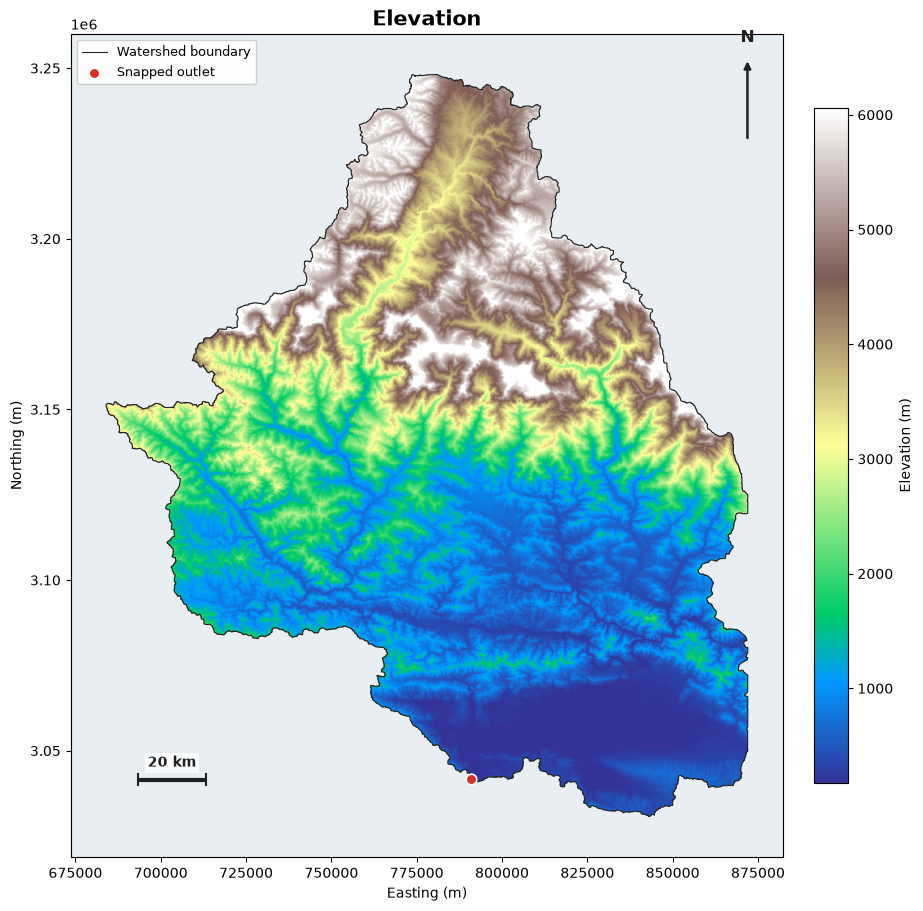

In [2]:
# Cell 2: Elevation
layer_path = save_clipped_raster(watershed_dem_path, "elevation")
show_saved_layer("elevation", layer_path, "Elevation", "Elevation (m)", cmap="terrain", pct=(2, 98))


Saved: slope_deg.tif | slope_deg.png


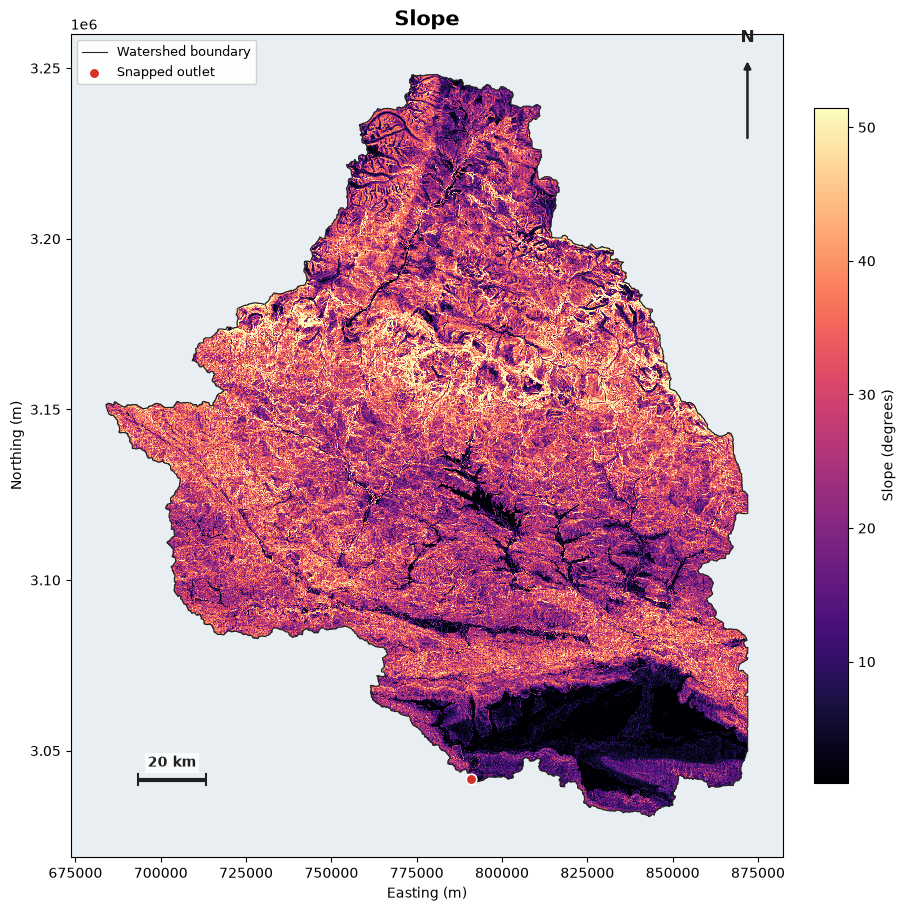

In [3]:
# Cell 3: Slope (degrees)
slope_path = create_whitebox_layer("slope_deg", "slope", watershed_dem_path, units="degrees")
show_saved_layer("slope_deg", slope_path, "Slope", "Slope (degrees)", cmap="magma", pct=(2, 98))


Saved: aspect.tif | aspect.png


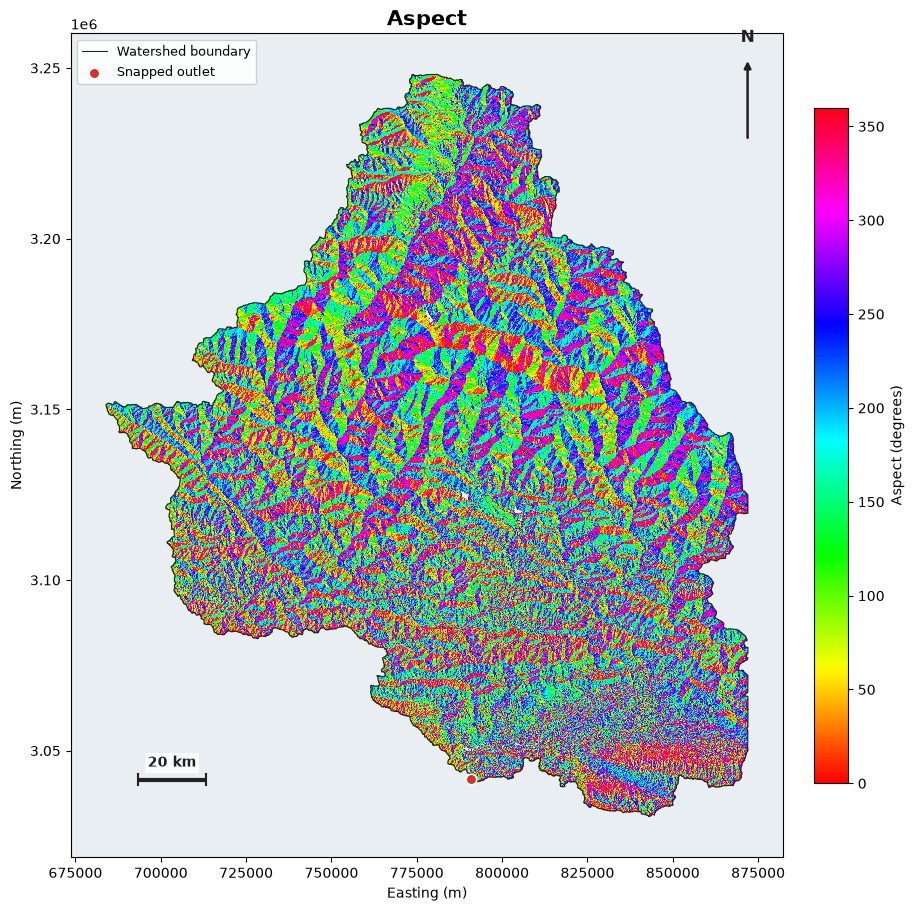

In [4]:
# Cell 4: Aspect (degrees clockwise from north)
aspect_path = create_whitebox_layer("aspect", "aspect", watershed_dem_path)
with rasterio.open(aspect_path, "r+") as dst:
    for _, block in dst.block_windows(1):
        values = dst.read(1, window=block)
        values[values < 0] = dst.nodata
        dst.write(values, 1, window=block)
show_saved_layer("aspect", aspect_path, "Aspect", "Aspect (degrees)", cmap="hsv", vlim=(0, 360), resampling=Resampling.nearest)


Saved: profile_curvature.tif | profile_curvature.png


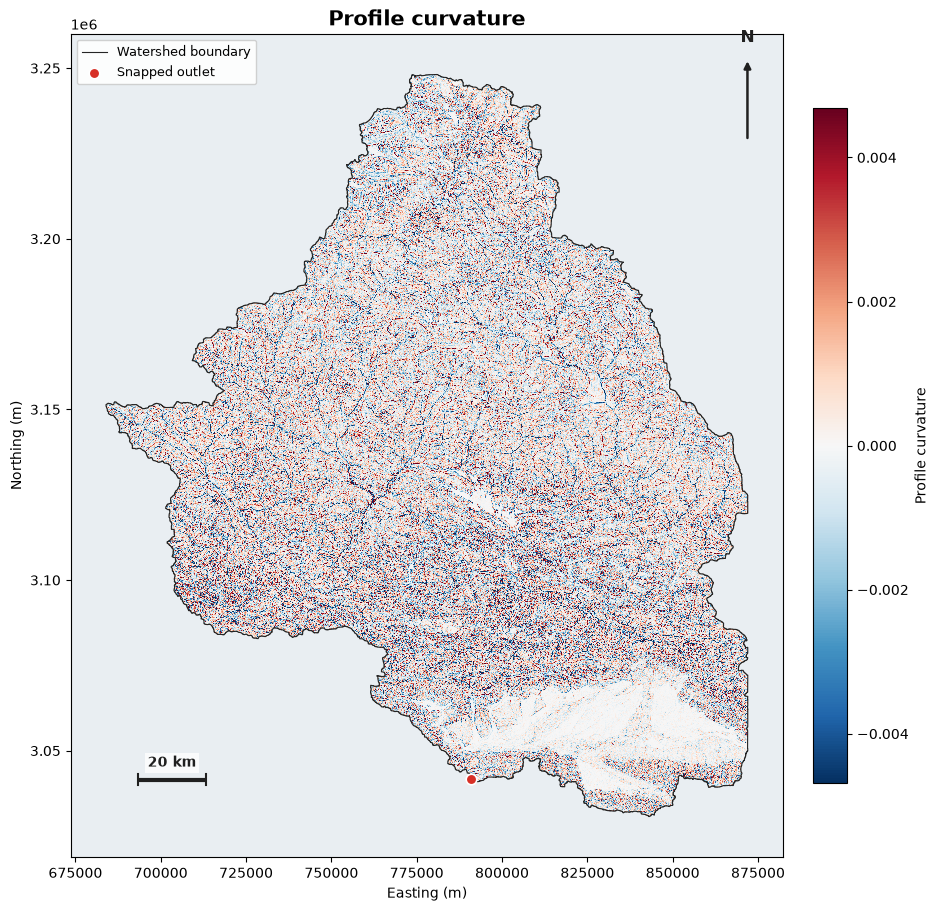

In [5]:
# Cell 5: Profile curvature
profile_curvature_path = create_whitebox_layer("profile_curvature", "profile_curvature", watershed_dem_path)
show_saved_layer("profile_curvature", profile_curvature_path, "Profile curvature", "Profile curvature", cmap="RdBu_r", symmetric=True, pct=(2, 98))


Saved: plan_curvature.tif | plan_curvature.png


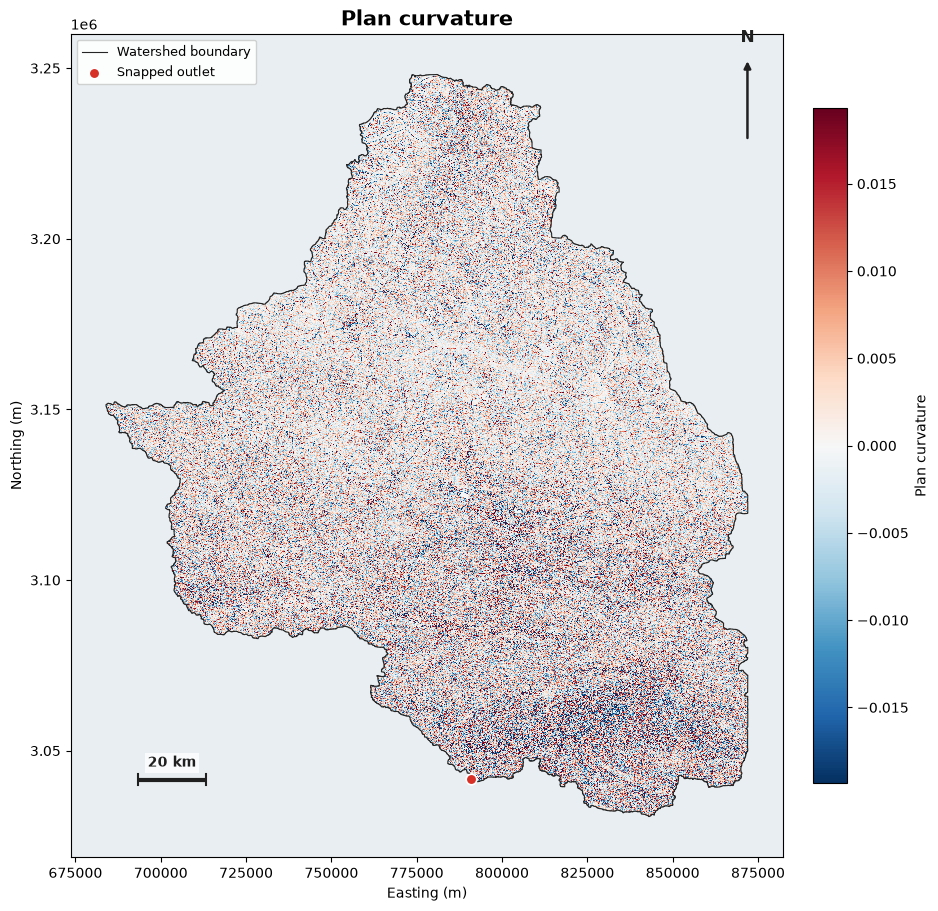

In [6]:
# Cell 6: Plan curvature
plan_curvature_path = create_whitebox_layer("plan_curvature", "plan_curvature", watershed_dem_path)
show_saved_layer("plan_curvature", plan_curvature_path, "Plan curvature", "Plan curvature", cmap="RdBu_r", symmetric=True, pct=(2, 98))


Saved: hillshade.tif | hillshade.png


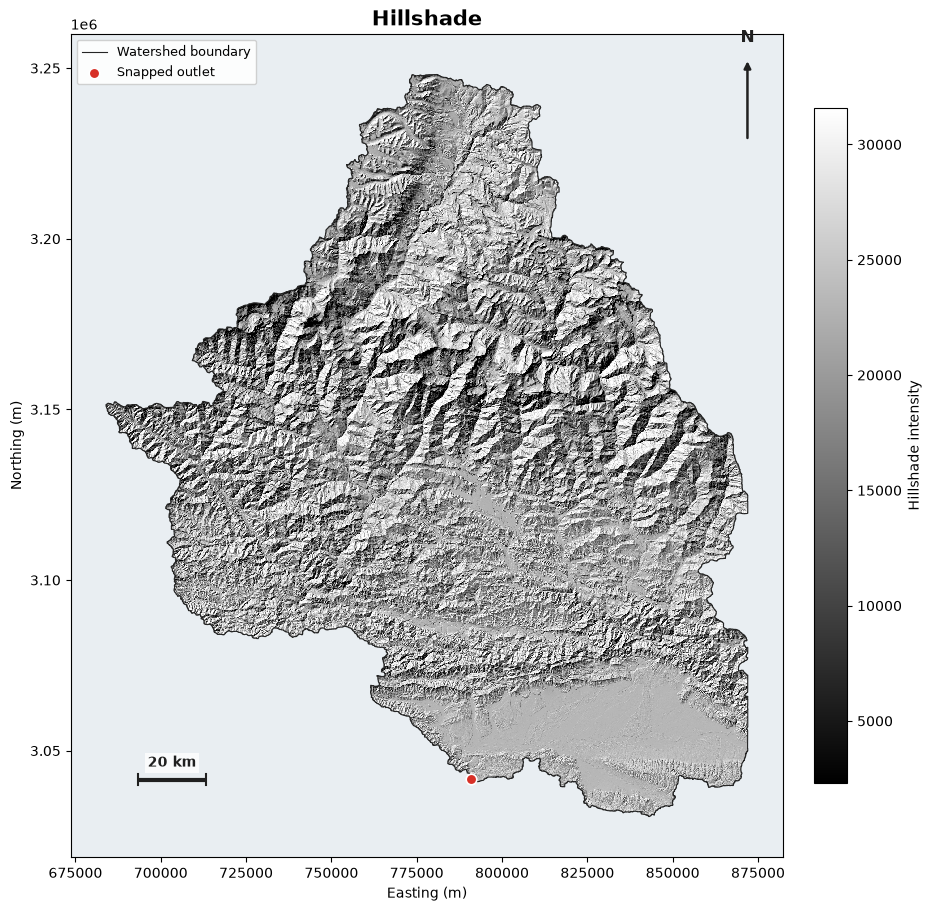

In [7]:
# Cell 7: Hillshade
hillshade_path = create_whitebox_layer("hillshade", "hillshade", watershed_dem_path, azimuth=315.0, altitude=45.0)
show_saved_layer("hillshade", hillshade_path, "Hillshade", "Hillshade intensity", cmap="gray", pct=(2, 98))


Saved: tpi_300m.tif | tpi_300m.png


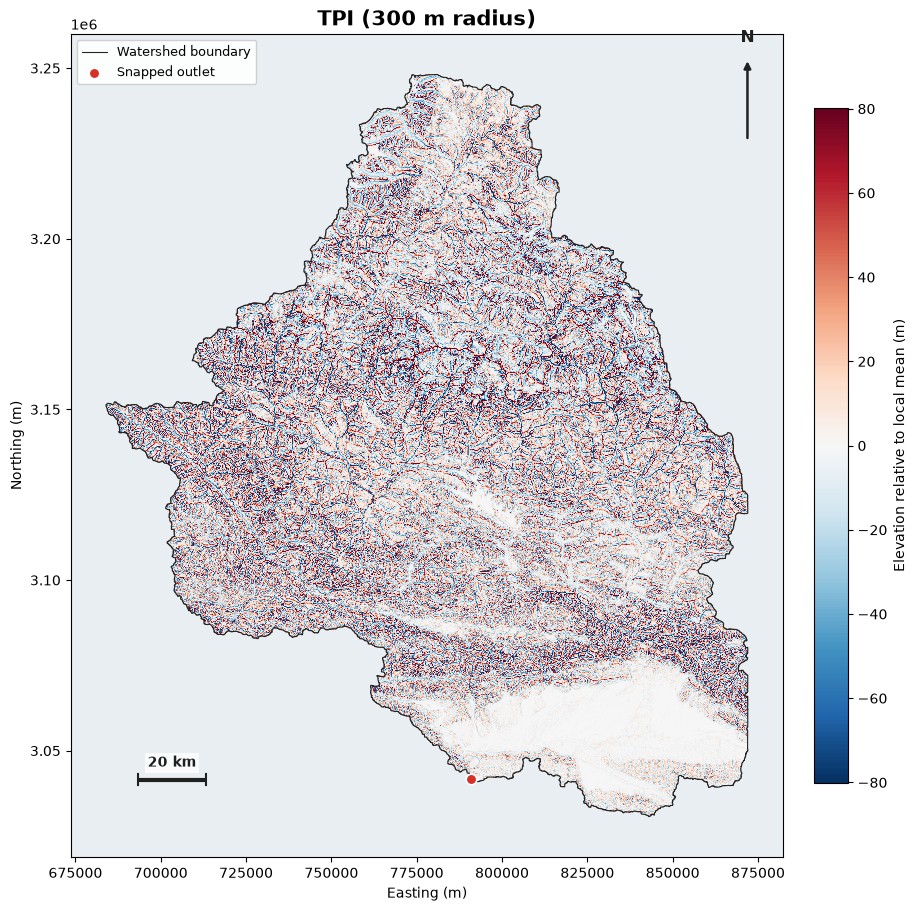

In [8]:
# Cell 8: Topographic position index (TPI, 300 m radius)
tpi_300_path = create_tpi_layer("tpi_300m", 300.0)
show_saved_layer("tpi_300m", tpi_300_path, "TPI (300 m radius)", "Elevation relative to local mean (m)", cmap="RdBu_r", symmetric=True, pct=(2, 98))


Saved: tpi_1km.tif | tpi_1km.png


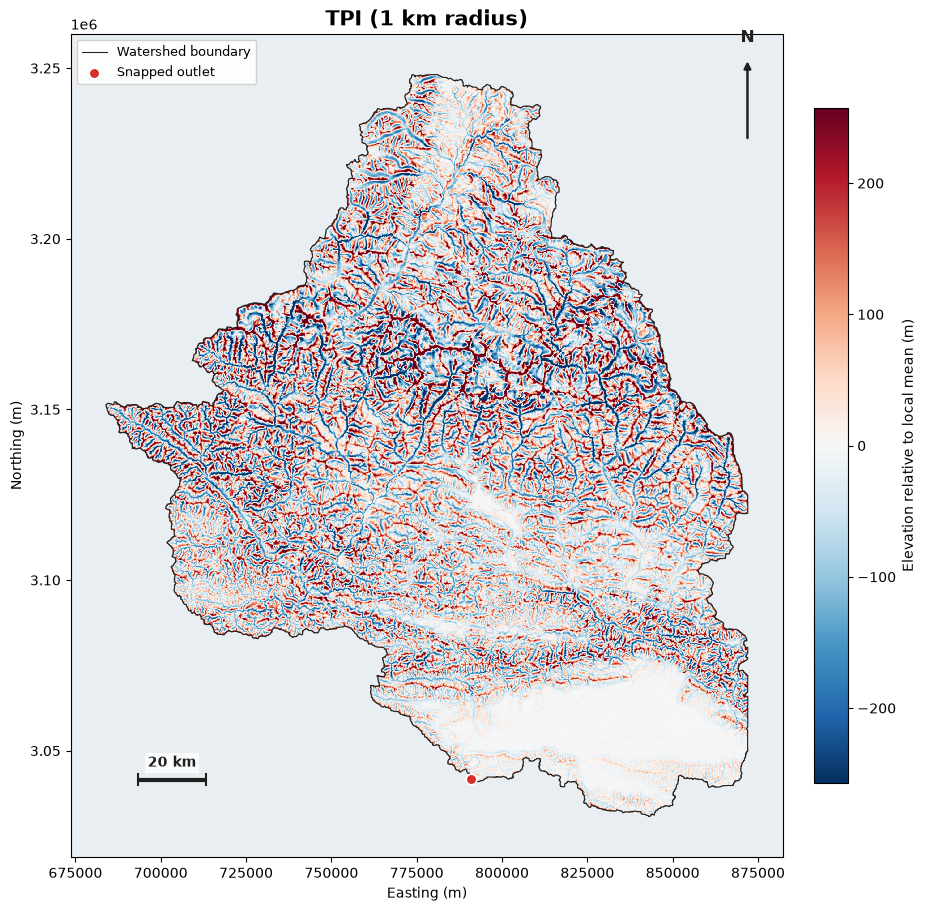

In [9]:
# Cell 9: Topographic position index (TPI, 1 km radius)
tpi_1km_path = create_tpi_layer("tpi_1km", 1000.0)
show_saved_layer("tpi_1km", tpi_1km_path, "TPI (1 km radius)", "Elevation relative to local mean (m)", cmap="RdBu_r", symmetric=True, pct=(2, 98))


Saved: tri_3x3.tif | tri_3x3.png


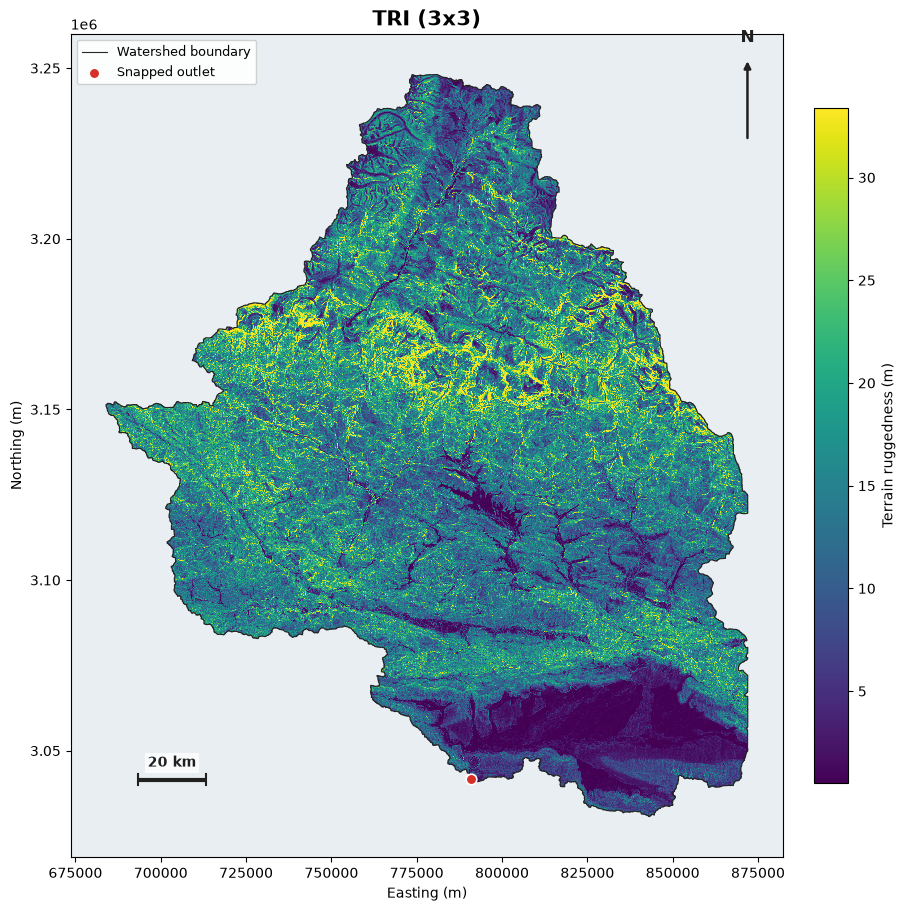

In [10]:
# Cell 10: Terrain ruggedness index (TRI, 3x3)
tri_path = create_whitebox_layer("tri_3x3", "ruggedness_index", watershed_dem_path)
show_saved_layer("tri_3x3", tri_path, "TRI (3x3)", "Terrain ruggedness (m)", cmap="viridis", pct=(2, 98))


Saved: relative_relief_1km.tif | relative_relief_1km.png


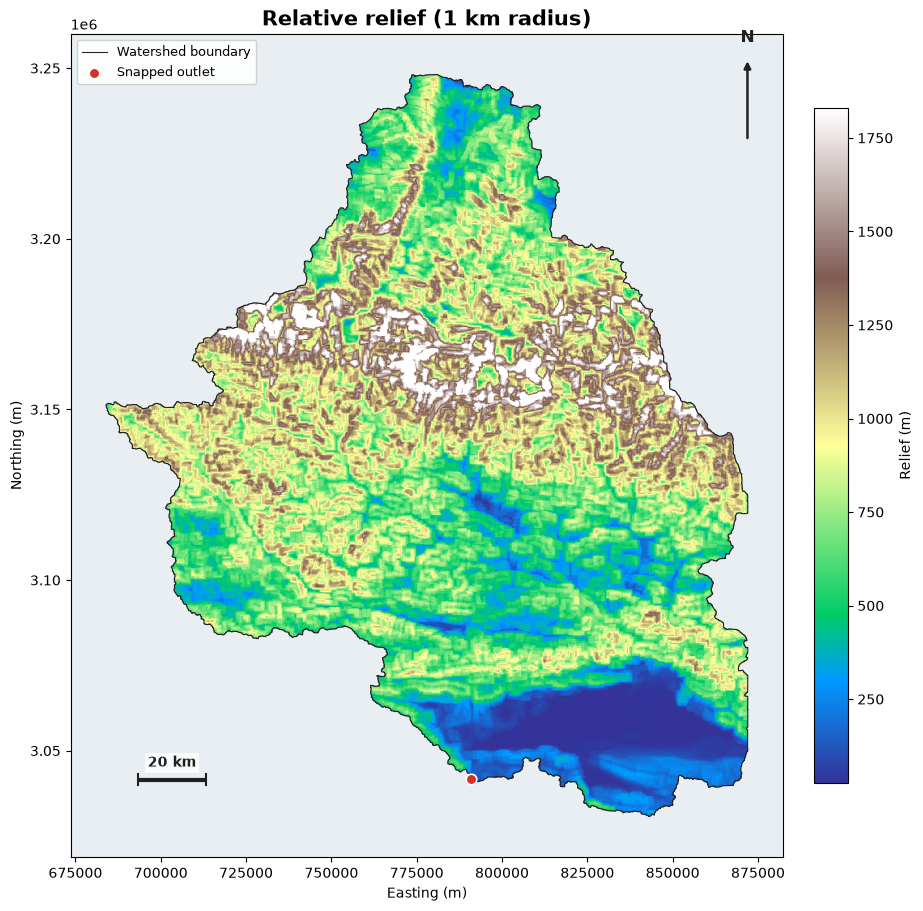

In [11]:
# Cell 11: Relative relief (1 km radius)
relief_window = 2 * round(1000.0 / cs) + 1
relief_path = create_whitebox_layer("relative_relief_1km", "range_filter", watershed_dem_path, filterx=relief_window, filtery=relief_window)
show_saved_layer("relative_relief_1km", relief_path, "Relative relief (1 km radius)", "Relief (m)", cmap="terrain", pct=(2, 98))


Saved: flow_accumulation_km2.tif | flow_accumulation_km2.png


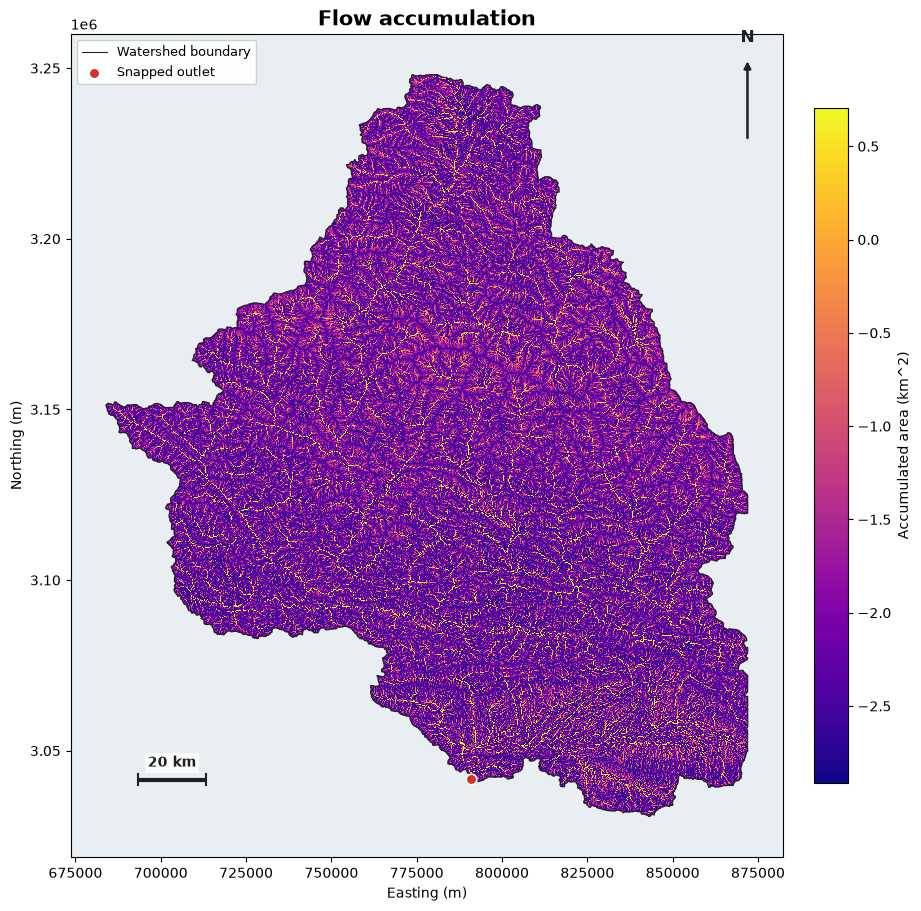

In [12]:
# Cell 12: Flow accumulation (km2, log scale)
aligned_flow_accum = align_to_watershed(flow_accumulation_path)
flow_km2 = aligned_flow_accum * (cell_area / 1_000_000.0)
show_layer(
    "flow_accumulation_km2", flow_km2, "Flow accumulation", "Accumulated area (km^2)",
    cmap="plasma", transform=np.log10, pct=(2, 98),
)
del flow_km2, aligned_flow_accum


Saved: stream_network_25km2.tif | stream_network_25km2.png | stream_network_25km2.gpkg


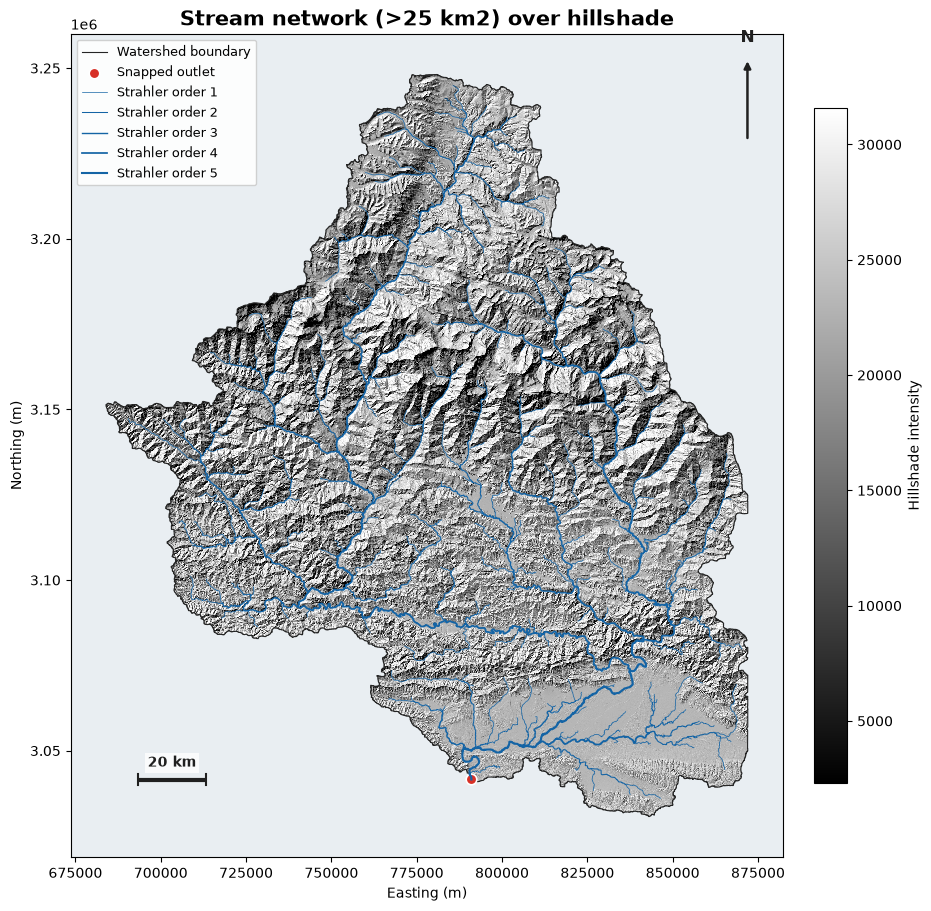

In [13]:
# Cell 13: Stream network (>25 km2) with Strahler order
stream_mask_full = create_stream_mask_full()
stream_order_full = feature_dir / "_stream_order_full.tif"
stream_vector_full = vector_dir / "_streams_full.shp"
stream_gpkg = vector_dir / "stream_network_25km2.gpkg"
run_whitebox("strahler_stream_order", flow_pointer_path, stream_mask_full, stream_order_full, zero_background=True)
run_whitebox("raster_streams_to_vector", stream_order_full, flow_pointer_path, stream_vector_full)
streams_gdf = gpd.read_file(stream_vector_full)
if streams_gdf.empty:
    raise ValueError("No streams exceed the 25 km2 accumulation threshold in this watershed.")
order_field = next((name for name in ("STRM_VAL", "strm_val", "VALUE", "value", "ORDER", "order") if name in streams_gdf.columns), None)
if order_field is None:
    raise ValueError(f"Stream vector has no Strahler-order field: {list(streams_gdf.columns)}")
streams_gdf = streams_gdf.rename(columns={order_field: "strahler_order"}).set_crs(crs, allow_override=True)
streams_gdf = gpd.clip(streams_gdf, watershed_gdf)
streams_gdf.to_file(stream_gpkg, layer="streams", driver="GPKG")
for suffix in (".shp", ".shx", ".dbf", ".prj", ".cpg"):
    stream_vector_full.with_suffix(suffix).unlink(missing_ok=True)
stream_order = align_to_watershed(stream_order_full)
stream_order[(stream_order <= 0) | ~valid_dem] = np.nan
stream_raster = save_watershed_tif(stream_order, "stream_network_25km2")
stream_order_full.unlink(missing_ok=True)
hillshade_raster = feature_dir / "hillshade.tif"

def draw_streams(ax):
    for order in sorted(streams_gdf["strahler_order"].dropna().astype(int).unique()):
        part = streams_gdf[streams_gdf["strahler_order"].astype(int) == order]
        line_parts = []
        for geometry in part.geometry:
            lines = geometry.geoms if geometry.geom_type == "MultiLineString" else (geometry,)
            for line in lines:
                line_parts.extend((np.asarray(line.coords), np.array([[np.nan, np.nan]])))
        if line_parts:
            coordinates = np.concatenate(line_parts)
            ax.plot(
                coordinates[:, 0], coordinates[:, 1], color="#1464a5",
                linewidth=0.25 + 0.25 * order,
                label=f"Strahler order {order}", zorder=7,
            )

stream_png = fig_dir / "stream_network_25km2.png"
fig = plot_raster_map(
    str(hillshade_raster), watershed_gdf, str(snapped_outlet_path),
    "Stream network (>25 km2) over hillshade", "Hillshade intensity",
    str(stream_png), cmap="gray", pct=(2, 98), resampling=Resampling.average,
    extra=draw_streams,
)
print(f"Saved: {stream_raster.name} | {stream_png.name} | {stream_gpkg.name}")
plt.show()
plt.close(fig)


Saved: distance_to_river.tif | distance_to_river.png


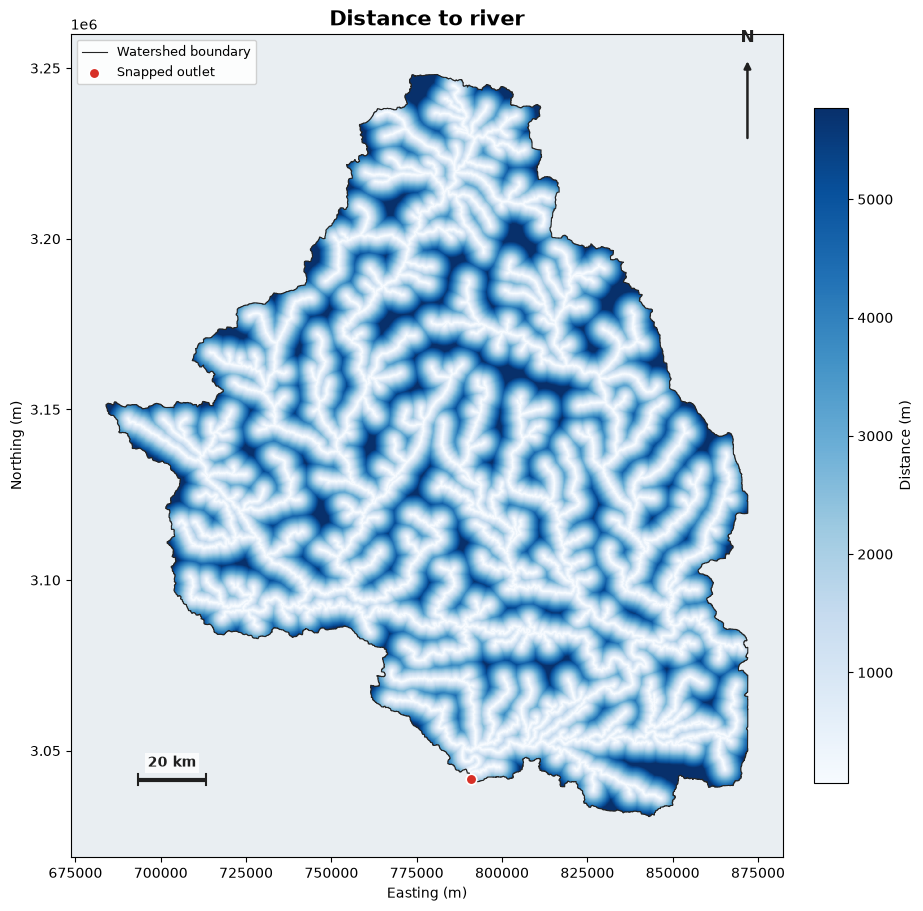

In [14]:
# Cell 14: Distance to river
stream_mask = np.isfinite(stream_order)
if not stream_mask.any():
    raise ValueError("The aligned stream network contains no watershed cells.")
distance_to_river = ndi.distance_transform_edt(~stream_mask, sampling=cs).astype("float32")
distance_to_river[~valid_dem] = np.nan
show_layer("distance_to_river", distance_to_river, "Distance to river", "Distance (m)", cmap="Blues", pct=(2, 98))
del distance_to_river, stream_order


Saved: hand.tif | hand.png


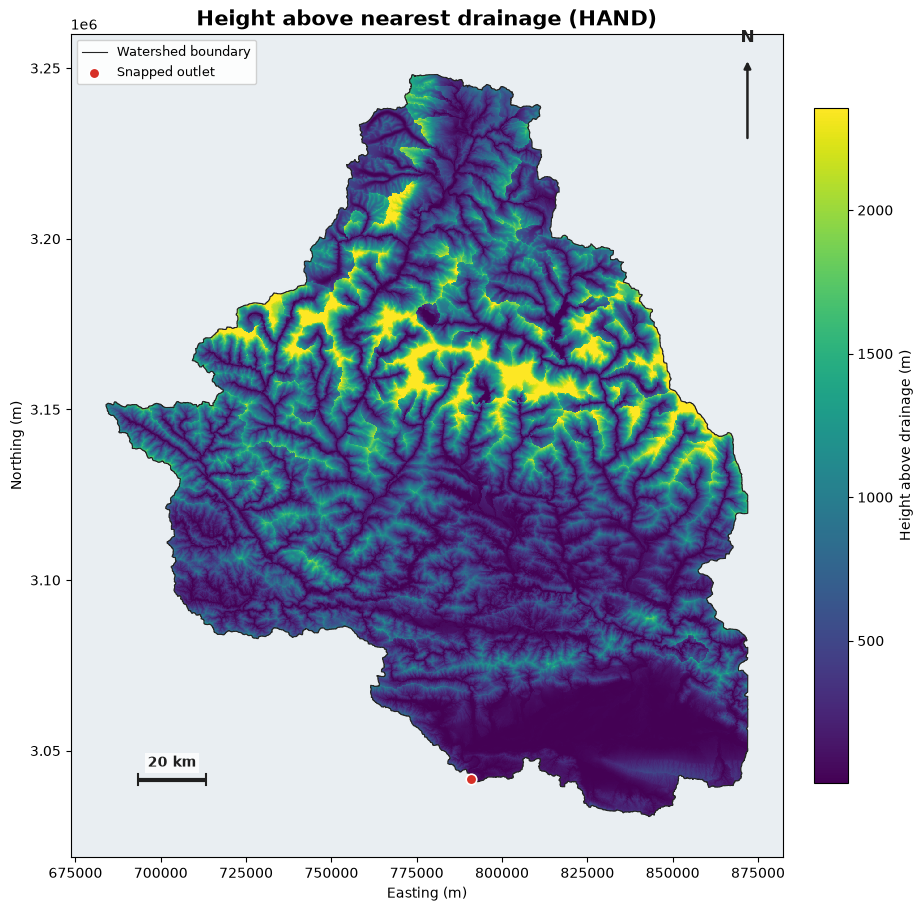

In [15]:
# Cell 15: Height above nearest drainage (HAND)
hand_full = feature_dir / "_hand_full.tif"
run_whitebox("elevation_above_stream", filled_dem_path, stream_mask_full, hand_full)
hand = align_to_watershed(hand_full)
hand[~valid_dem] = np.nan
show_layer("hand", hand, "Height above nearest drainage (HAND)", "Height above drainage (m)", cmap="viridis", pct=(2, 98))
hand_full.unlink(missing_ok=True)
stream_mask_full.unlink(missing_ok=True)
del hand


Saved: downstream_flow_length.tif | downstream_flow_length.png


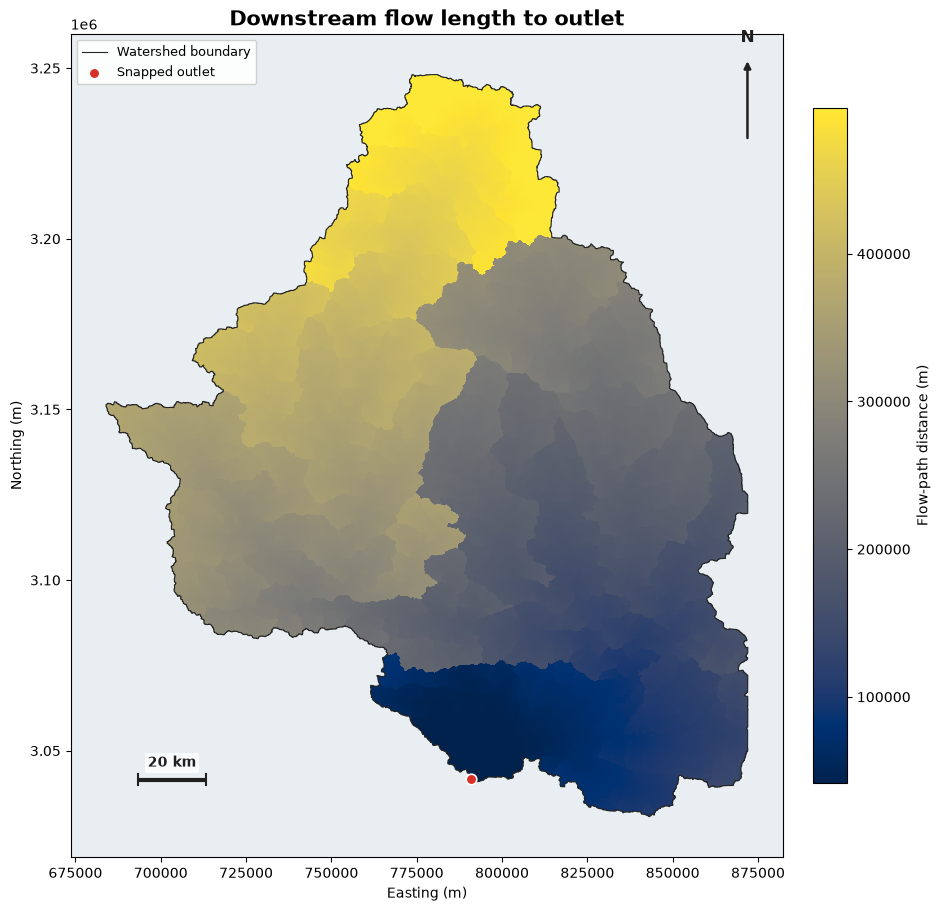

In [16]:
# Cell 16: Downstream flow length to outlet
outlet_seed_path = feature_dir / "_outlet_seed_full.tif"
with rasterio.open(flow_pointer_path) as src:
    outlet_points = gpd.read_file(snapped_outlet_path).to_crs(src.crs)
    seed = rasterize(
        [(geometry, 1) for geometry in outlet_points.geometry],
        out_shape=(src.height, src.width), transform=src.transform,
        fill=0, dtype="uint8",
    )
    seed_profile = src.profile.copy()
seed_profile.update(dtype="uint8", nodata=0, count=1, compress="lzw")
with rasterio.open(outlet_seed_path, "w", **seed_profile) as dst:
    dst.write(seed, 1)
del seed
flow_length_full = feature_dir / "_downstream_length_full.tif"
run_whitebox("downslope_distance_to_stream", filled_dem_path, outlet_seed_path, flow_length_full)
downstream_length = align_to_watershed(flow_length_full)
downstream_length[~valid_dem] = np.nan
show_layer("downstream_flow_length", downstream_length, "Downstream flow length to outlet", "Flow-path distance (m)", cmap="cividis", pct=(2, 98))
flow_length_full.unlink(missing_ok=True)
outlet_seed_path.unlink(missing_ok=True)
del downstream_length


Saved: dinf_specific_catchment_area.tif | dinf_specific_catchment_area.png


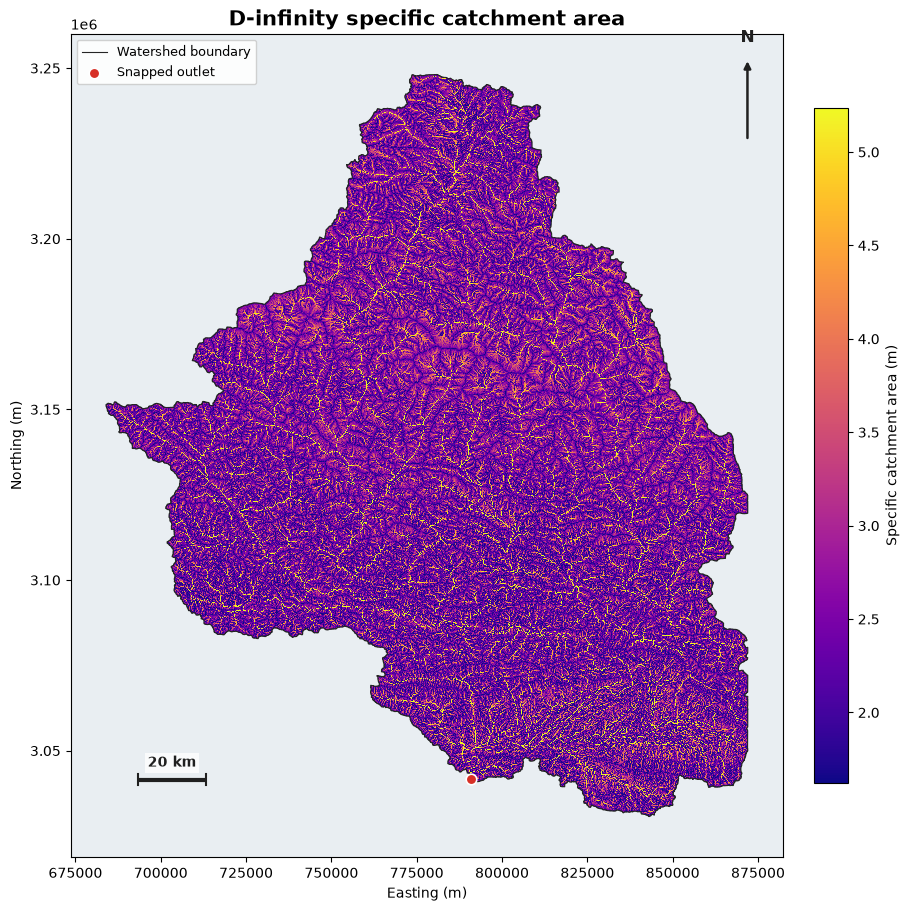

In [17]:
# Cell 17: D-infinity specific catchment area
sca_full = feature_dir / "_dinf_sca_full.tif"
run_whitebox("d_inf_flow_accumulation", filled_dem_path, sca_full, out_type="sca", log=False, clip=False)
sca = align_to_watershed(sca_full)
sca[(sca <= 0) | ~valid_dem] = np.nan
sca_full.unlink(missing_ok=True)
show_layer("dinf_specific_catchment_area", sca, "D-infinity specific catchment area", "Specific catchment area (m)", cmap="plasma", transform=np.log10, pct=(2, 98))


Saved: twi.tif | twi.png


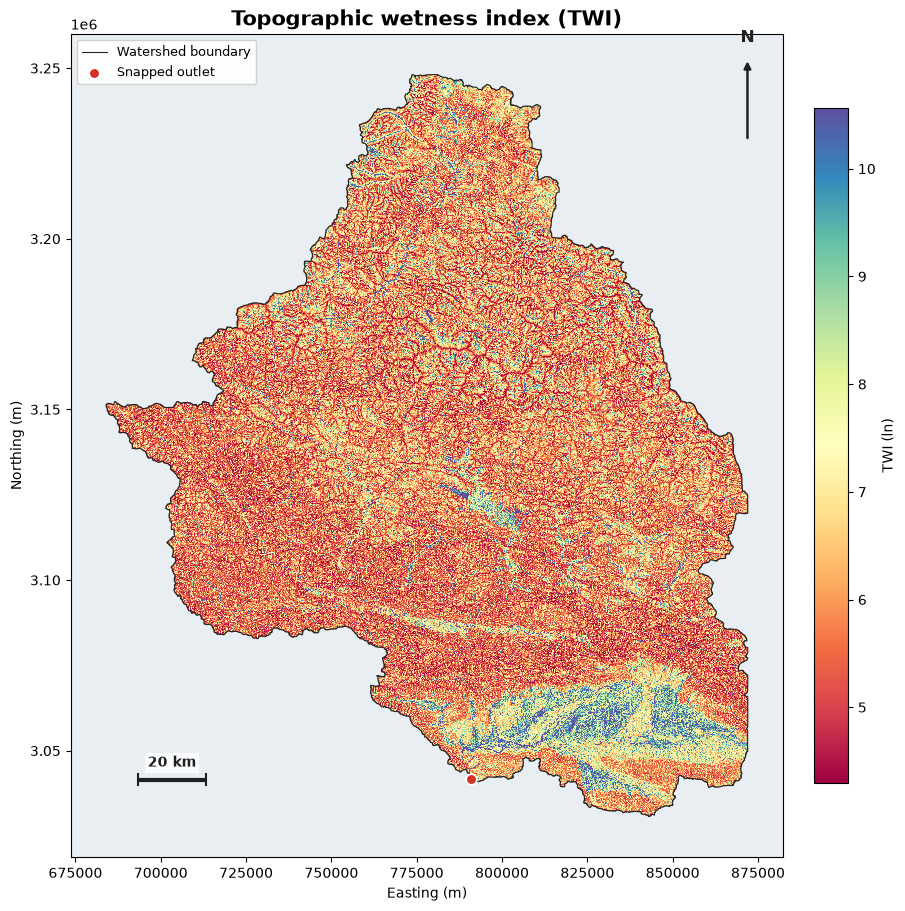

In [18]:
# Cell 18: Topographic wetness index (TWI)
with rasterio.open(slope_path) as src:
    slope_degrees = src.read(1).astype("float32")
    slope_degrees[src.read_masks(1) == 0] = np.nan
slope_tan = np.tan(np.radians(slope_degrees))
del slope_degrees
slope_tan = np.maximum(slope_tan, 1e-3)
twi = np.log(sca / slope_tan)
twi[~valid_dem | ~np.isfinite(sca)] = np.nan
show_layer("twi", twi, "Topographic wetness index (TWI)", "TWI (ln)", cmap="Spectral", pct=(2, 98))
del twi


Saved: spi.tif | spi.png


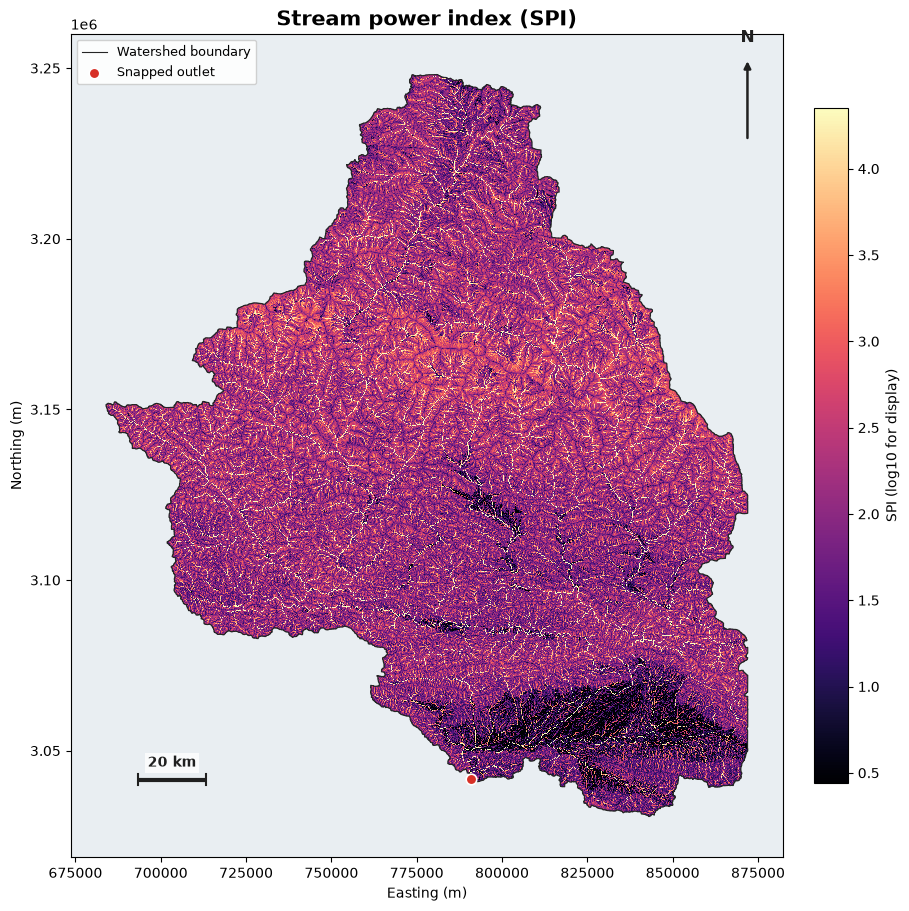

In [19]:
# Cell 19: Stream power index (SPI)
spi = sca * slope_tan
spi[~valid_dem | ~np.isfinite(sca)] = np.nan
show_layer("spi", spi, "Stream power index (SPI)", "SPI (log10 for display)", cmap="magma", transform=np.log10, pct=(2, 98))
del spi


Saved: sti.tif | sti.png


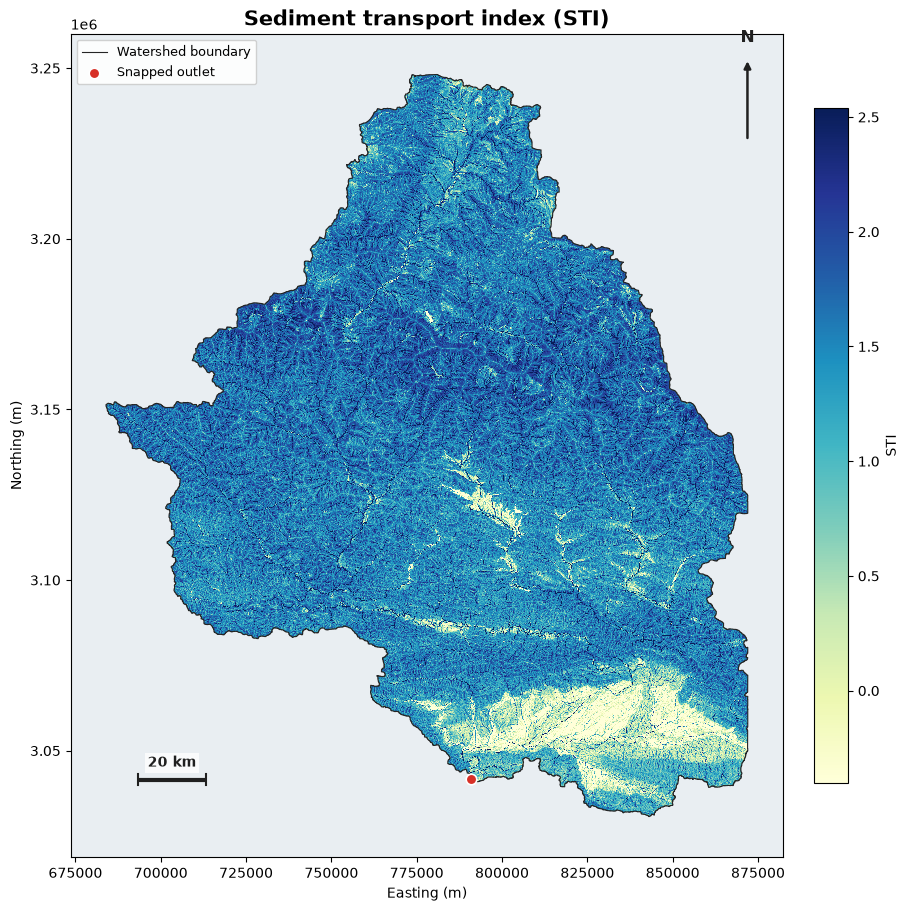

In [20]:
# Cell 20: Sediment transport index (STI)
slope_sin = np.maximum(slope_tan / np.sqrt(1 + slope_tan**2), 1e-6)
sti = (sca / 22.13) ** 0.6 * (slope_sin / 0.0896) ** 1.3
sti[~valid_dem | ~np.isfinite(sca)] = np.nan
show_layer("sti", sti, "Sediment transport index (STI)", "STI", cmap="YlGnBu", transform=np.log10, pct=(2, 98))
del sti, sca, slope_tan, slope_sin
